# 11. Modelo base: línea base trivial y regresión logística

**Qué hacemos** (ruta A del enunciado, con estructura temporal y espacial):

- **Línea base trivial:** `DummyClassifier(strategy="prior")`: predice siempre la clase
  mayoritaria («tardía») y da a todos la misma probabilidad (ROC-AUC = 0,5).
- **Modelo base:** **regresión logística** dentro del Pipeline del capítulo 10.
- **Métrica principal: ROC-AUC** (cap. 1 y 3). También accuracy, recall, F1,
  Average Precision, Brier, matriz de confusión, curvas ROC/PR y calibración.
- **Validación:** cruzada **temporal** con *gap* de 7 días (la misma estructura que la
  partición). Como esquema adicional, **bloques espaciales**, reportado por separado.
- **Incertidumbre:** bootstrap que remuestrea **pedidos** (las líneas de un pedido comparten
  etiqueta) y diferencia pareada frente a la línea base.
- **Diagnóstico:** curva de aprendizaje, ACF de residuos (tiempo), I de Moran de residuos
  (espacio), desempeño por subgrupos y deriva en la prueba.

In [1]:
from pathlib import Path
import re, sys, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Markdown, display

project_root = Path.cwd().resolve()
while not (project_root / "_config.yml").exists():
    if project_root.parent == project_root:
        raise FileNotFoundError("No se encontró _config.yml. Ejecuta el notebook dentro de la carpeta del libro.")
    project_root = project_root.parent
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

for _folder in ("tables", "figures"):          # se crean si no existen
    (project_root / _folder).mkdir(exist_ok=True)

from src.project_utils import *

configure_plots()
pd.set_option("display.max_columns", 80)
pd.set_option("display.width", 170)
pd.set_option("display.max_colwidth", 70)
TABLES = project_root / "tables"

def md_out(text):
    display(Markdown(text))

import json
from scipy import stats
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import cross_validate, GroupKFold
from sklearn.metrics import (make_scorer, recall_score, f1_score, roc_curve, RocCurveDisplay,
                             PrecisionRecallDisplay, ConfusionMatrixDisplay, roc_auc_score, brier_score_loss)
from sklearn.calibration import calibration_curve
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.graphics.tsaplots import plot_acf
warnings.filterwarnings("ignore", message="Found unknown categories")

decision = pd.read_csv(TABLES / "decision_poblacion.csv").iloc[0]
incl = not bool(decision["excluir_cancelados"])
train, test = load_train(include_canceled=incl), load_test(include_canceled=incl)
sel = json.loads((TABLES / "modelo_elegido.json").read_text(encoding="utf-8"))
conjuntos = json.loads((TABLES / "conjuntos_variables.json").read_text(encoding="utf-8"))
nl, nlog, cat = sel["num_lin"], sel["num_log"], sel["cat"]
COLS = nl + nlog + cat
Xtr, ytr, Xte, yte = train[COLS], train[TARGET], test[COLS], test[TARGET]
gtr, gte = train[ORDER_COL], test[ORDER_COL]
folds = temporal_folds(train[DATE_COL])
md_out(f"- **Variables del modelo** ({sel['conjunto']}): {', '.join(f'`{c}`' for c in COLS)}\n"
       f"- **Entrenamiento:** {es(len(train), 0)} líneas, {es(gtr.nunique(), 0)} pedidos, {train[DATE_COL].min():%Y-%m-%d} a {train[DATE_COL].max():%Y-%m-%d}; tardías {es(ytr.mean(), 1, pct=True)}\n"
       f"- **Prueba:** {es(len(test), 0)} líneas, {es(gte.nunique(), 0)} pedidos, {test[DATE_COL].min():%Y-%m-%d} a {test[DATE_COL].max():%Y-%m-%d}; tardías {es(yte.mean(), 1, pct=True)}\n"
       f"- Pedidos cancelados/fraude excluidos: {'sí' if not incl else 'no'} (cap. 9)")

- **Variables del modelo** (C · modo × jornada (interacción)): `mode_x_daypart`
- **Entrenamiento:** 137.043 líneas, 45.669 pedidos, 2015-01-01 a 2017-04-14; tardías 57,3 %
- **Prueba:** 34.583 líneas, 16.850 pedidos, 2017-04-22 a 2018-01-31; tardías 57,3 %
- Pedidos cancelados/fraude excluidos: sí (cap. 9)

## 1. Hiperparámetro de regularización (solo con validación cruzada temporal)

La regresión logística usa penalización L2 con intensidad `1/C`. Se elige `C` por ROC-AUC
medio en los pliegues temporales del **entrenamiento**; la prueba no interviene.

In [2]:
grid = [0.001, 0.01, 0.1, 1.0, 10.0]
filas = []
for C in grid:
    s = cross_validate(make_model_pipeline(nl, nlog, cat, C=C), Xtr, ytr, cv=folds, scoring="roc_auc")["test_score"]
    filas.append({"C": C, "ROC-AUC media": s.mean(), "desv.": s.std()})
tuning = pd.DataFrame(filas)
tuning.to_csv(TABLES / "ajuste_C.csv", index=False)
C_best = float(tuning.loc[tuning["ROC-AUC media"].idxmax(), "C"])
display(tuning.round(5))
md_out(f"`C` elegido: **{C_best}**. Las diferencias entre valores son mínimas: con pocas variables y n grande la regularización casi no influye.")
def nuevo_modelo(cols=None):
    if cols is None:
        return make_model_pipeline(nl, nlog, cat, C=C_best)
    return make_model_pipeline(cols["num_lin"], cols["num_log"], cols["cat"], C=C_best)

,C,ROC-AUC media,desv.
0,0.001,0.74137,0.00996
1,0.010,0.77433,0.00350
2,0.100,0.77403,0.00329
3,1.000,0.77403,0.00329
4,10.000,0.77414,0.00316


`C` elegido: **0.01**. Las diferencias entre valores son mínimas: con pocas variables y n grande la regularización casi no influye.

## 2. Validación cruzada: temporal (principal), bloques espaciales y aleatoria por pedido

Se reporta media ± desviación entre pliegues. El esquema **temporal** es el que corresponde
al uso previsto (predecir pedidos futuros). Los otros dos se reportan **por separado** para
comprobar si la estructura espacial o la agrupación inflan el desempeño.

In [3]:
scoring = {"accuracy": "accuracy",
           "recall": make_scorer(recall_score, zero_division=0), "f1": make_scorer(f1_score, zero_division=0),
           "roc_auc": "roc_auc", "average_precision": "average_precision", "brier": "neg_brier_score"}
celdas = spatial_cells(train[LAT], train[LON]).to_numpy()
esquemas = {
    "Temporal con gap 7 d (principal)": (folds, None),
    "Bloques espaciales (GroupKFold por celda 1°)": (list(GroupKFold(n_splits=5).split(Xtr, ytr, groups=celdas)), None),
    "Aleatoria agrupada por pedido (GroupKFold)": (list(GroupKFold(n_splits=5).split(Xtr, ytr, groups=gtr)), None),
}
modelos = {"Dummy (prior)": lambda: DummyClassifier(strategy="prior"), "Regresión logística": nuevo_modelo,
           "Sensibilidad: LR con todas las variables del pedido (D)": lambda: nuevo_modelo(conjuntos["D · pedido completo + interacción (sin destino)"])}
filas = []
for esquema, (cv_, _) in esquemas.items():
    for nombre, fabrica in modelos.items():
        if esquema != "Temporal con gap 7 d (principal)" and nombre.startswith("Sensibilidad"):
            continue
        Xuse = train[sum(conjuntos["D · pedido completo + interacción (sin destino)"].values(), [])] if nombre.startswith("Sensibilidad") else Xtr
        r = cross_validate(fabrica(), Xuse, ytr, cv=cv_, scoring=scoring)
        fila = {"esquema": esquema, "modelo": nombre}
        for k in scoring:
            v = r[f"test_{k}"] * (-1 if k == "brier" else 1)
            fila[f"{k}"] = f"{v.mean():.4f} ± {v.std():.4f}"
            fila[f"_{k}_mean"] = v.mean()
        filas.append(fila)
cv_res = pd.DataFrame(filas)
cv_res.to_csv(TABLES / "cv_resumen.csv", index=False)
display(cv_res[[c for c in cv_res.columns if not c.startswith("_")]])

,esquema,modelo,accuracy,recall,f1,roc_auc,average_precision,brier
0,Temporal con gap 7 d (principal),Dummy (prior),0.5734 ± 0.0025,1.0000 ± 0.0000,0.7288 ± 0.0020,0.5000 ± 0.0000,0.5734 ± 0.0025,0.2446 ± 0.0004
1,Temporal con gap 7 d (principal),Regresión logística,0.7216 ± 0.0019,0.5839 ± 0.0047,0.7063 ± 0.0032,0.7743 ± 0.0035,0.8230 ± 0.0029,0.1773 ± 0.0011
2,Temporal con gap 7 d (principal),Sensibilidad: LR con todas las variables del pedido (D),0.7216 ± 0.0019,0.5839 ± 0.0047,0.7063 ± 0.0032,0.7717 ± 0.0024,0.8539 ± 0.0021,0.1774 ± 0.0011
3,Bloques espaciales (GroupKFold por celda 1°),Dummy (prior),0.5728 ± 0.0021,1.0000 ± 0.0000,0.7284 ± 0.0017,0.5000 ± 0.0000,0.5728 ± 0.0021,0.2447 ± 0.0003
4,Bloques espaciales (GroupKFold por celda 1°),Regresión logística,0.7232 ± 0.0052,0.5864 ± 0.0090,0.7082 ± 0.0066,0.7759 ± 0.0059,0.8236 ± 0.0032,0.1759 ± 0.0016
5,Aleatoria agrupada por pedido (GroupKFold),Dummy (prior),0.5732 ± 0.0030,1.0000 ± 0.0000,0.7287 ± 0.0025,0.5000 ± 0.0000,0.5732 ± 0.0030,0.2447 ± 0.0004
6,Aleatoria agrupada por pedido (GroupKFold),Regresión logística,0.7227 ± 0.0054,0.5852 ± 0.0100,0.7074 ± 0.0068,0.7753 ± 0.0025,0.8235 ± 0.0025,0.1760 ± 0.0016


**Interpretación.** En validación temporal la regresión logística obtiene un ROC-AUC
≈ 0,77 frente a 0,50 del Dummy, y un accuracy ≈ 0,72 frente a ≈ 0,57. Los tres esquemas
dan resultados casi idénticos: como el objetivo no tiene autocorrelación espacial (cap. 8)
ni temporal (cap. 7), la validación aleatoria **no** estaría inflada en este caso; aun así el
esquema que se reporta como principal es el temporal. El modelo con todas las variables del
pedido (sensibilidad) no mejora: la señal sin fuga está en el modo de envío y, para Same
Day, en la jornada del pedido.

## 3. Ajuste final y evaluación única en la prueba

Ambos modelos se ajustan con todo el entrenamiento y se evalúan **una sola vez** en la
prueba, con umbral 0,5.

In [4]:
dummy = DummyClassifier(strategy="prior").fit(Xtr, ytr)
lr = nuevo_modelo().fit(Xtr, ytr)
p_dummy, p_lr = dummy.predict_proba(Xte)[:, 1], lr.predict_proba(Xte)[:, 1]
pred_dummy, pred_lr = dummy.predict(Xte), (p_lr >= 0.5).astype(int)
res = pd.DataFrame([classification_metrics(yte, pred_dummy, p_dummy), classification_metrics(yte, pred_lr, p_lr)],
                   index=["Dummy (prior)", "Regresión logística"])
res.to_csv(TABLES / "resultados_prueba.csv")
techo = pd.read_csv(TABLES / "techo_sin_fuga.csv")
tasa_celda = train.groupby("mode_x_daypart")[TARGET].mean()
p_tabla = test["mode_x_daypart"].map(tasa_celda).fillna(ytr.mean()).to_numpy()
res.loc["Referencia: tabla de tasas modo × jornada (techo empírico)"] = classification_metrics(yte, (p_tabla >= 0.5).astype(int), p_tabla)
res.to_csv(TABLES / "resultados_prueba.csv")
display(res.round(4))
md_out(f"**ROC-AUC en la prueba (DataCo sin fuga): {es(res.loc['Regresión logística', 'ROC-AUC'], 4)}** frente a {es(res.loc['Dummy (prior)', 'ROC-AUC'], 2)} de la línea base.")

,Accuracy,Recall,F1,ROC-AUC,Average Precision,Brier
Dummy (prior),0.5730,1.0000,0.7286,0.5000,0.5730,0.2447
Regresión logística,0.7248,0.5885,0.7102,0.7746,0.8239,0.1753
Referencia: tabla de tasas modo × jornada (techo empírico),0.7248,0.5885,0.7102,0.7746,0.8239,0.1743


**ROC-AUC en la prueba (DataCo sin fuga): 0,7746** frente a 0,50 de la línea base.

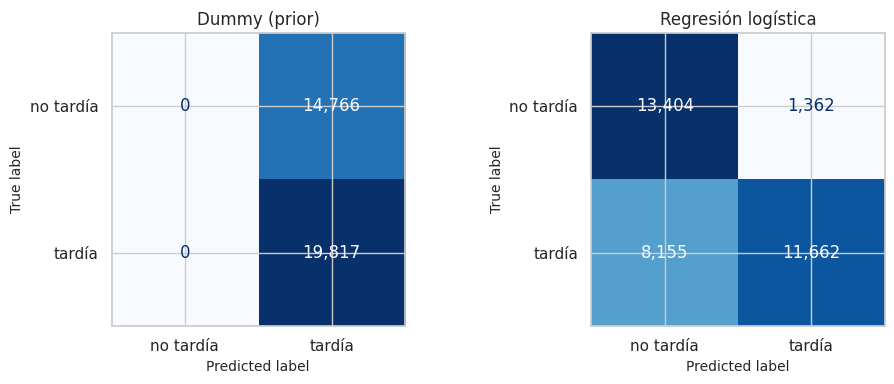

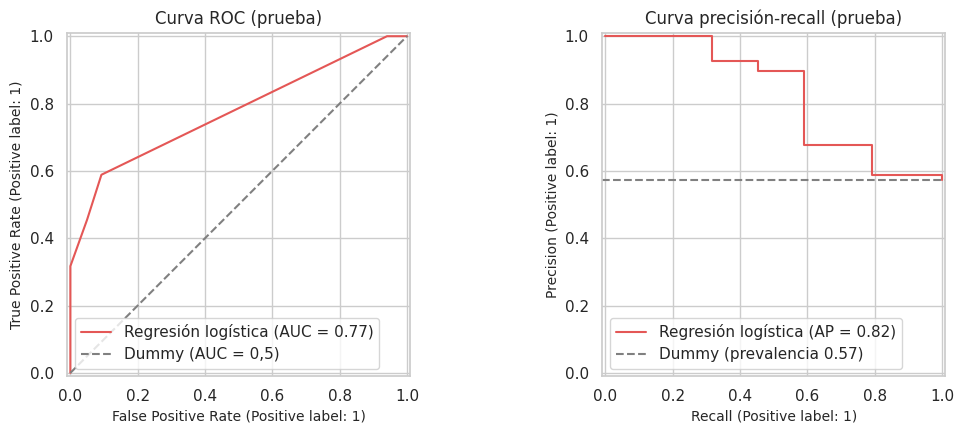

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, nombre, pred in zip(axes, ["Dummy (prior)", "Regresión logística"], [pred_dummy, pred_lr]):
    ConfusionMatrixDisplay.from_predictions(yte, pred, display_labels=["no tardía", "tardía"], ax=ax, colorbar=False, cmap="Blues", values_format=",")
    ax.set_title(nombre)
plt.tight_layout(); save_figure(fig, "11_matrices_confusion.png"); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
RocCurveDisplay.from_predictions(yte, p_lr, name="Regresión logística", ax=axes[0], color="#e45756")
axes[0].plot([0, 1], [0, 1], "--", color="gray", label="Dummy (AUC = 0,5)"); axes[0].legend(); axes[0].set_title("Curva ROC (prueba)")
PrecisionRecallDisplay.from_predictions(yte, p_lr, name="Regresión logística", ax=axes[1], color="#e45756")
axes[1].axhline(yte.mean(), ls="--", color="gray", label=f"Dummy (prevalencia {yte.mean():.2f})"); axes[1].legend(); axes[1].set_title("Curva precisión-recall (prueba)")
plt.tight_layout(); save_figure(fig, "11_curvas_roc_pr.png"); plt.show()

**Interpretación.** El Dummy predice «tardía» para todos: recall 1, accuracy igual a la
prevalencia y ROC-AUC 0,5. La regresión logística pone arriba a First Class y Same Day de la
tarde (siempre tardíos), luego Second Class (80 %), Standard (40 %) y al final Same Day de la
mañana (nunca tardío). La curva ROC es una **poligonal de pocos vértices** porque el puntaje
solo toma 8 valores. El modelo **iguala** a la tabla de tasas por modo × jornada (el techo
empírico sin fuga, cap. 9): no queda señal por extraer con estas variables. Con umbral 0,5 los
Standard se predicen «no tardía», y como el 40 % de ellos sí se retrasa, el recall de la clase
tardía queda en ≈ 0,6: esos retrasos son aleatorios en la simulación y **no son predecibles**.

## 4. Calibración

Se revisa en la prueba y con predicciones **fuera de pliegue** del entrenamiento. El **Brier**
(menor es mejor) se compara con el de predecir siempre la prevalencia.

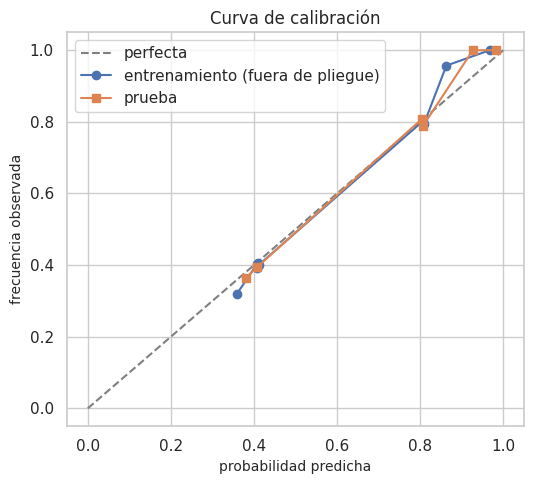

,conjunto,Brier modelo,Brier prevalencia,mejora_%
0,prueba,0.1753,0.2447,28.3363
1,entrenamiento OOF,0.1773,0.2446,27.5376


In [6]:
oof = np.full(len(train), np.nan)
for tr_i, va_i in folds:
    oof[va_i] = nuevo_modelo().fit(Xtr.iloc[tr_i], ytr.iloc[tr_i]).predict_proba(Xtr.iloc[va_i])[:, 1]
m_oof = ~np.isnan(oof)
f_te, mp_te = calibration_curve(yte, p_lr, n_bins=10, strategy="quantile")
f_oof, mp_oof = calibration_curve(ytr[m_oof], oof[m_oof], n_bins=10, strategy="quantile")
fig, ax = plt.subplots(figsize=(5.5, 5))
ax.plot([0, 1], [0, 1], "--", color="gray", label="perfecta")
ax.plot(mp_oof, f_oof, "o-", label="entrenamiento (fuera de pliegue)"); ax.plot(mp_te, f_te, "s-", label="prueba")
ax.set_xlabel("probabilidad predicha"); ax.set_ylabel("frecuencia observada"); ax.legend(); ax.set_title("Curva de calibración")
plt.tight_layout(); save_figure(fig, "11_calibracion.png"); plt.show()
cal = pd.DataFrame([{"conjunto": "prueba", "Brier modelo": brier_score_loss(yte, p_lr), "Brier prevalencia": brier_score_loss(yte, np.full(len(yte), ytr.mean()))},
                    {"conjunto": "entrenamiento OOF", "Brier modelo": brier_score_loss(ytr[m_oof], oof[m_oof]), "Brier prevalencia": brier_score_loss(ytr[m_oof], np.full(m_oof.sum(), ytr.mean()))}])
cal["mejora_%"] = 100 * (1 - cal["Brier modelo"] / cal["Brier prevalencia"])
cal.to_csv(TABLES / "calibracion.csv", index=False)
display(cal.round(4))

**Interpretación.** Las probabilidades están **bien calibradas** en el rango central (los
puntos siguen la diagonal): cuando el modelo dice 40 % (Standard) se retrasa ≈ 40 %, y cuando
dice 80 % (Second Class), ≈ 80 %. En los extremos la regularización las encoge un poco (dice
≈ 0,9 donde la tasa es 1 y ≈ 0,1 donde es 0). El Brier mejora frente a
predecir la prevalencia. La calibración es la esperable en una regresión logística con
variables categóricas y n grande.

## 5. Umbral de decisión

El umbral 0,5 no es obligatorio. Se elige un umbral alternativo **solo con las predicciones
fuera de pliegue del entrenamiento** (máximo índice de Youden) y se evalúa en la prueba.

In [7]:
fpr, tpr, thr = roc_curve(ytr[m_oof], oof[m_oof])
umbral = float(thr[np.argmax(tpr - fpr)])
pred_alt = (p_lr >= umbral).astype(int)
umb = pd.DataFrame([classification_metrics(yte, pred_lr, p_lr), classification_metrics(yte, pred_alt, p_lr)],
                   index=["umbral 0,5", f"umbral Youden OOF = {umbral:.3f}"])
umb.to_csv(TABLES / "umbral_alternativo.csv")
display(umb.round(4))

,Accuracy,Recall,F1,ROC-AUC,Average Precision,Brier
"umbral 0,5",0.7248,0.5885,0.7102,0.7746,0.8239,0.1753
umbral Youden OOF = 0.806,0.6663,0.4545,0.6095,0.7746,0.8239,0.1753


**Interpretación.** Como el puntaje solo toma 8 valores, cambiar el umbral equivale a decidir
qué celdas se marcan como «tardía». Youden (elegido sin mirar la prueba) sube el umbral y deja
fuera a Second Class: pierde recall y accuracy a cambio de menos falsas alarmas. El umbral es una **decisión
operativa** (costo de una falsa alarma frente al de un retraso no anticipado) que no cambia el
ROC-AUC; por eso la métrica principal es independiente del umbral.

## 6. Intervalos de confianza: bootstrap por pedido

Remuestrear filas subestimaría la incertidumbre, porque las líneas de un pedido comparten
etiqueta. Se remuestrean **pedidos completos** (1.000 réplicas), intervalo percentil del 95 %.
Para comparar con el Dummy se usan **los mismos pedidos** remuestreados en ambos modelos.

In [8]:
ic = cluster_bootstrap(yte, pred_lr, p_lr, gte, B=1000)
ic_d = cluster_bootstrap(yte, pred_dummy, p_dummy, gte, B=1000)
dif = paired_cluster_bootstrap(yte, pred_lr, p_lr, pred_dummy, p_dummy, gte, B=1000)
ic.to_csv(TABLES / "intervalos_bootstrap_logistica.csv"); ic_d.to_csv(TABLES / "intervalos_bootstrap_dummy.csv"); dif.to_csv(TABLES / "diferencias_vs_dummy.csv")
md_out("**Regresión logística (prueba):**"); display(ic.round(4))
md_out("**Dummy (prueba):**"); display(ic_d.round(4))
md_out("**Diferencia regresión logística − Dummy (mismos pedidos remuestreados):**"); display(dif.round(4))
auc_ic = ic.loc["ROC-AUC"]
md_out(f"ROC-AUC = **{es(auc_ic.iloc[0], 4)}** (IC 95 %: {es(auc_ic.iloc[1], 4)} – {es(auc_ic.iloc[2], 4)}). "
       f"La mejora en ROC-AUC frente al Dummy es {es(dif.loc['ROC-AUC', 'Diferencia'], 4)} (IC: {es(dif.loc['ROC-AUC', 'IC inferior'], 4)} – {es(dif.loc['ROC-AUC', 'IC superior'], 4)}): "
       + ("**el intervalo no incluye 0**." if dif.loc['ROC-AUC', 'IC inferior'] > 0 else "el intervalo incluye 0."))

**Regresión logística (prueba):**

,Estimación,IC 95 % inferior,IC 95 % superior
Métrica,,,
Accuracy,0.7248,0.7170,0.7325
Recall,0.5885,0.5763,0.5998
F1,0.7102,0.7004,0.7192
ROC-AUC,0.7746,0.7668,0.7825
Average Precision,0.8239,0.8168,0.8309
Brier,0.1753,0.1725,0.1783


**Dummy (prueba):**

,Estimación,IC 95 % inferior,IC 95 % superior
Métrica,,,
Accuracy,0.5730,0.5638,0.5823
Recall,1.0000,1.0000,1.0000
F1,0.7286,0.7211,0.7360
ROC-AUC,0.5000,0.5000,0.5000
Average Precision,0.5730,0.5638,0.5823
Brier,0.2447,0.2433,0.2460


**Diferencia regresión logística − Dummy (mismos pedidos remuestreados):**

,Diferencia,IC inferior,IC superior
Métrica,,,
Accuracy,0.1518,0.1374,0.1662
Recall,-0.4115,-0.4237,-0.4002
F1,-0.0184,-0.0298,-0.0076
ROC-AUC,0.2746,0.2668,0.2825
Average Precision,0.2508,0.2437,0.2580
Brier,-0.0693,-0.0722,-0.0664


ROC-AUC = **0,7746** (IC 95 %: 0,7668 – 0,7825). La mejora en ROC-AUC frente al Dummy es 0,2746 (IC: 0,2668 – 0,2825): **el intervalo no incluye 0**.

## 7. Curva de aprendizaje

Para cada pliegue temporal se entrena con fracciones crecientes de los datos **más recientes**
anteriores al *gap* y se valida en el bloque siguiente (ROC-AUC).

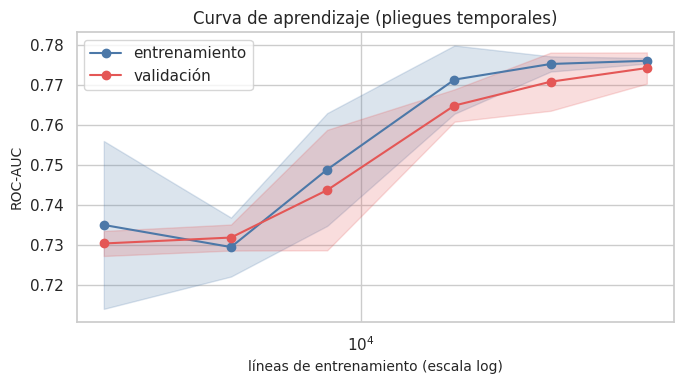

,n_train,AUC_train,AUC_train_sd,AUC_valid,AUC_valid_sd
fracción,,,,,
0.02,1566.2,0.7350,0.0211,0.7303,0.0031
0.05,3916.4,0.7294,0.0074,0.7318,0.0033
0.10,7833.0,0.7489,0.0141,0.7437,0.0151
0.25,19583.0,0.7714,0.0086,0.7649,0.0041
0.50,39166.8,0.7753,0.0019,0.7709,0.0073
1.00,78334.0,0.7761,0.0007,0.7743,0.0039


In [9]:
fracs = [0.02, 0.05, 0.1, 0.25, 0.5, 1.0]
filas = []
for k, (tr_i, va_i) in enumerate(folds):
    for f in fracs:
        sub = tr_i[-max(200, int(f * len(tr_i))):]
        m = nuevo_modelo().fit(Xtr.iloc[sub], ytr.iloc[sub])
        filas.append({"pliegue": k, "fracción": f, "n_train": len(sub),
                      "AUC_train": roc_auc_score(ytr.iloc[sub], m.predict_proba(Xtr.iloc[sub])[:, 1]),
                      "AUC_valid": roc_auc_score(ytr.iloc[va_i], m.predict_proba(Xtr.iloc[va_i])[:, 1])})
lc = pd.DataFrame(filas)
curva = lc.groupby("fracción").agg(n_train=("n_train", "mean"), AUC_train=("AUC_train", "mean"), AUC_train_sd=("AUC_train", "std"),
                                   AUC_valid=("AUC_valid", "mean"), AUC_valid_sd=("AUC_valid", "std"))
curva.to_csv(TABLES / "curva_aprendizaje.csv")
fig, ax = plt.subplots(figsize=(7, 4))
for col, c in [("AUC_train", "#4c78a8"), ("AUC_valid", "#e45756")]:
    ax.plot(curva["n_train"], curva[col], "o-", color=c, label=col.replace("AUC_", "").replace("train", "entrenamiento").replace("valid", "validación"))
    ax.fill_between(curva["n_train"], curva[col] - curva[f"{col}_sd"], curva[col] + curva[f"{col}_sd"], color=c, alpha=0.2)
ax.set_xscale("log"); ax.set_xlabel("líneas de entrenamiento (escala log)"); ax.set_ylabel("ROC-AUC"); ax.legend(); ax.set_title("Curva de aprendizaje (pliegues temporales)")
plt.tight_layout(); save_figure(fig, "11_curva_aprendizaje.png"); plt.show()
display(curva.round(4))

**Interpretación.** Las curvas de entrenamiento y validación están **pegadas** en todos los
tamaños: **no hay sobreajuste**. El ROC-AUC de validación sube hasta ≈ 40.000 líneas (las
celdas pequeñas, como Same Day, necesitan casos para estimarse bien frente a la penalización) y
luego se estabiliza en el techo sin fuga: la muestra es **suficiente** y más datos no
mejorarían este modelo. El límite es la información disponible sin fuga, no el tamaño de muestra.

## 8. Interpretación de coeficientes (odds ratios)

Las numéricas están estandarizadas; en las categóricas, `OneHotEncoder(drop='first')` elimina
la primera categoría, que es la referencia. Son asociaciones ajustadas, no efectos causales.

,variable,categoría_referencia
0,mode_x_daypart,First Class | AM


,variable,coeficiente,odds_ratio,tipo
0,cat__mode_x_daypart_Same Day | AM,-4.4040,0.0122,indicador de categoría
1,cat__mode_x_daypart_Standard Class | AM,-2.7253,0.0655,indicador de categoría
2,cat__mode_x_daypart_Standard Class | PM,-2.7075,0.0667,indicador de categoría
3,cat__mode_x_daypart_First Class | PM,1.7545,5.7807,indicador de categoría
4,cat__mode_x_daypart_Same Day | PM,1.1331,3.1052,indicador de categoría
5,cat__mode_x_daypart_Second Class | AM,-0.9213,0.3980,indicador de categoría
6,cat__mode_x_daypart_Second Class | PM,-0.9040,0.4049,indicador de categoría


Intercepto: 2.333 (log-odds de la categoría de referencia).

,P predicha,tasa observada (train),líneas
mode_x_daypart,,,
First Class | AM,0.9116,1.0000,10056
First Class | PM,0.9835,1.0000,10986
Same Day | AM,0.1120,0.0000,3911
Same Day | PM,0.9697,1.0000,3456
Second Class | AM,0.8040,0.7967,13600
Second Class | PM,0.8067,0.8001,13283
Standard Class | AM,0.4032,0.3964,41003
Standard Class | PM,0.4075,0.4008,40748


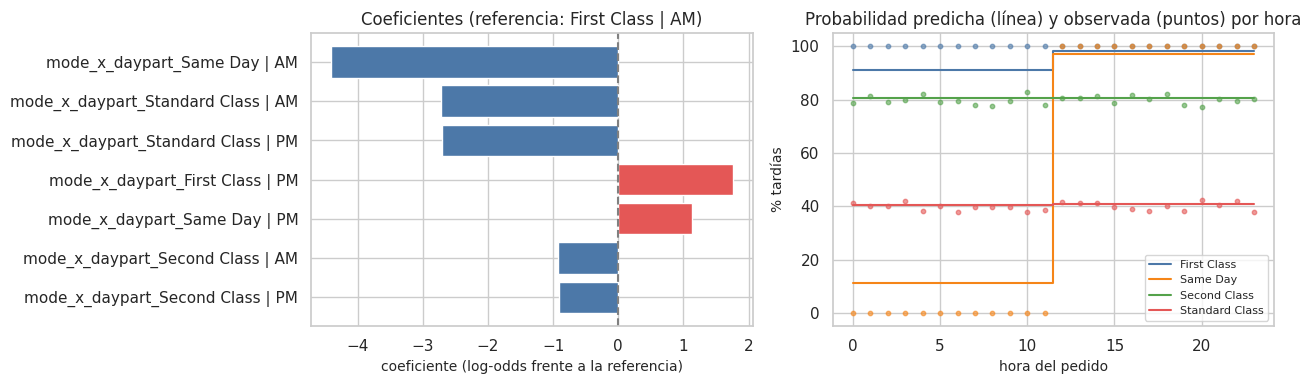

In [10]:
orr = odds_ratio_table(lr)
refs = onehot_reference_table(lr, cat)
orr.to_csv(TABLES / "odds_ratios.csv", index=False); refs.to_csv(TABLES / "categorias_referencia_onehot.csv", index=False)
display(refs); display(orr.round(4))
md_out(f"Intercepto: {lr.named_steps['clf'].intercept_[0]:.3f} (log-odds de la categoría de referencia).")

# Probabilidad predicha por celda y por hora, frente a la tasa observada en entrenamiento
horas = np.arange(24)
grid_h = pd.DataFrame([(m, h) for m in sorted(train["shipping_mode"].unique()) for h in horas], columns=["shipping_mode", "order_hour"])
grid_h["order_afternoon"] = (grid_h["order_hour"] >= 12).astype(int)
grid_h["mode_x_daypart"] = grid_h["shipping_mode"] + np.where(grid_h["order_afternoon"] == 1, " | PM", " | AM")
grid_h["order_hour_sin"], grid_h["order_hour_cos"] = np.sin(2 * np.pi * grid_h["order_hour"] / 24), np.cos(2 * np.pi * grid_h["order_hour"] / 24)
for c in COLS:
    if c not in grid_h:
        grid_h[c] = train[c].mode().iloc[0] if c in cat else train[c].median()
grid_h["p"] = lr.predict_proba(grid_h[COLS])[:, 1]
prob_celda = (grid_h.groupby("mode_x_daypart")["p"].mean().rename("P predicha").to_frame()
              .join(train.groupby("mode_x_daypart")[TARGET].agg(["mean", "size"]).rename(columns={"mean": "tasa observada (train)", "size": "líneas"})))
prob_celda.to_csv(TABLES / "probabilidad_por_celda.csv")
display(prob_celda.round(4))
obs_h = train.groupby(["shipping_mode", "order_hour"])[TARGET].mean().rename("obs").reset_index()
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
o = orr.iloc[::-1]
axes[0].barh(o["variable"].str.replace("cat__", "").str.replace("num__", ""), o["coeficiente"], color=np.where(o["coeficiente"] > 0, "#e45756", "#4c78a8"))
axes[0].axvline(0, color="gray", ls="--"); axes[0].set_xlabel("coeficiente (log-odds frente a la referencia)")
axes[0].set_title(f"Coeficientes (referencia: {refs.iloc[0, 1]})")
for (m, g), c in zip(grid_h.groupby("shipping_mode"), ["#4c78a8", "#f58518", "#54a24b", "#e45756"]):
    axes[1].step(g["order_hour"], 100 * g["p"], where="mid", color=c, label=m)
    ob = obs_h[obs_h["shipping_mode"] == m]
    axes[1].scatter(ob["order_hour"], 100 * ob["obs"], color=c, s=10, alpha=0.6)
axes[1].set_xlabel("hora del pedido"); axes[1].set_ylabel("% tardías"); axes[1].legend(fontsize=8)
axes[1].set_title("Probabilidad predicha (línea) y observada (puntos) por hora")
plt.tight_layout(); save_figure(fig, "11_odds_ratios.png"); plt.show()

**Interpretación de los coeficientes.**

- La referencia es la primera categoría (orden alfabético), **First Class | AM**. Cada
  coeficiente es el cambio en log-odds frente a ella. Hay **separación casi completa**: cuatro
  celdas tienen tasa observada de 0 % o 100 % (First Class y Same Day), y sin penalización sus
  coeficientes tenderían a ±∞. La penalización L2 elegida por validación (`C` = 0,01) los
  acota y **encoge** las probabilidades extremas hacia la media (por ejemplo, 0,91 en lugar de 1
  para First Class | AM, que además queda distinta de First Class | PM solo porque la
  referencia se absorbe en el intercepto). Eso apenas afecta al **orden** (ROC-AUC); lo
  interpretable son las **probabilidades predichas** de la tabla.
- **Same Day | AM** tiene el coeficiente más negativo (nunca se retrasa) y **Same Day | PM**
  queda al nivel de First Class (siempre se retrasa): es la hora de corte del mediodía.
- **Paradoja de la promesa:** los envíos más rápidos prometidos son los que más se retrasan.
  First Class promete 1 día y tarda 2; Standard promete 4 y tarda entre 2 y 6. El riesgo
  depende de **lo ajustada que es la promesa**, no de la velocidad del transporte. Una
  recomendación operativa directa sería **revisar la promesa de First Class** y el corte de Same
  Day, más que priorizar pedidos uno a uno.
- Son asociaciones en datos simulados; no prueban causalidad.

## 9. Diagnóstico de residuos: dependencia temporal y espacial

En clasificación, el residuo es `y − p̂`. Si el modelo dejara estructura sin capturar, los
residuos promediados por día estarían autocorrelacionados (ACF, Ljung-Box) o los residuos
por celda espacial tendrían I de Moran significativa.

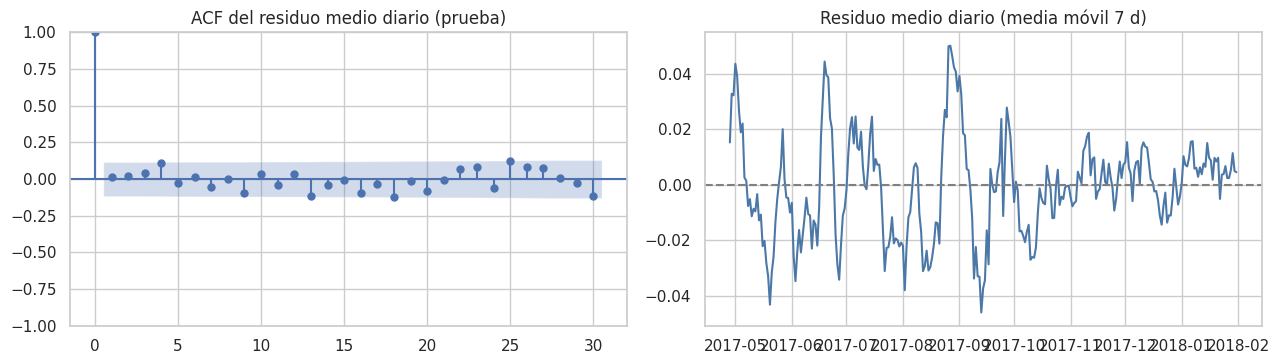

,diagnóstico,estadístico,p
0,"Ljung-Box residuo diario, rezago 7",5.1598,0.6405
1,"Ljung-Box residuo diario, rezago 14",13.5084,0.4869
2,"Ljung-Box residuo diario, rezago 28",36.9455,0.1201
3,I de Moran del residuo por celda (132 celdas),-0.0099,0.9120


In [11]:
res_te = test.assign(resid=yte - p_lr)
dia = res_te.groupby(res_te[DATE_COL].dt.normalize())["resid"].mean()
lb = acorr_ljungbox(dia, lags=[7, 14, 28], return_df=True)
cel = res_te.assign(c=spatial_cells(res_te[LAT], res_te[LON]).to_numpy()).groupby("c").agg(n=("resid", "size"), r=("resid", "mean"), lat=(LAT, "mean"), lon=(LON, "mean"))
cel = cel[cel["n"] >= 30]
mi_res = morans_i(cel["r"], knn_weights(cel["lat"], cel["lon"], k=8))
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
plot_acf(dia, lags=30, ax=axes[0]); axes[0].set_title("ACF del residuo medio diario (prueba)")
axes[1].plot(dia.index, dia.rolling(7).mean(), color="#4c78a8"); axes[1].axhline(0, color="gray", ls="--")
axes[1].set_title("Residuo medio diario (media móvil 7 d)")
plt.tight_layout(); save_figure(fig, "11_residuos_tiempo.png"); plt.show()
diag = pd.DataFrame([{"diagnóstico": f"Ljung-Box residuo diario, rezago {k}", "estadístico": r.lb_stat, "p": r.lb_pvalue} for k, r in lb.iterrows()]
                    + [{"diagnóstico": f"I de Moran del residuo por celda ({len(cel)} celdas)", "estadístico": mi_res["I"], "p": mi_res["p_permutacion"]}])
diag.to_csv(TABLES / "diagnostico_residuos.csv", index=False)
display(diag.round(4))

**Interpretación.** Si Ljung-Box y Moran no rechazan, los residuos no tienen dependencia
temporal ni espacial: el modelo no deja sin capturar estructura de tiempo o espacio. Esto es
coherente con el EDA (capítulos 7 y 8). Lo que el modelo no explica es variación
**idiosincrática** de cada pedido, no un patrón estructural.

## 10. Desempeño por subgrupos y deriva en la prueba

Se revisa si el modelo rinde parecido por mercado, segmento, modo de envío y periodo
(antes/después del cambio de régimen de octubre de 2017, cap. 7). Solo grupos con ≥ 300 líneas
y ambas clases. También se mide la deriva de covariables entre entrenamiento y prueba (PSI),
como diagnóstico **posterior** a la evaluación (no se usa para decidir nada).

In [12]:
Fte = test.assign(p=p_lr, pred=pred_lr, periodo=np.where(test[DATE_COL] >= "2017-10-01", "desde oct-2017 (1 línea/pedido)", "abr–sep 2017"))
def por_grupo(col, min_n=300):
    filas = []
    for g, d_ in Fte.groupby(col):
        if len(d_) < min_n or d_[TARGET].nunique() < 2:
            continue
        filas.append({"variable": col, "grupo": g, "n": len(d_), "tardías_%": 100 * d_[TARGET].mean(),
                      "ROC-AUC": roc_auc_score(d_[TARGET], d_["p"]), "Accuracy": (d_[TARGET] == d_["pred"]).mean(),
                      "Recall": recall_score(d_[TARGET], d_["pred"], zero_division=0)})
    return pd.DataFrame(filas)
sub = pd.concat([por_grupo(c) for c in ["market", "customer_segment", "shipping_mode", "periodo"]], ignore_index=True)
sub.to_csv(TABLES / "desempeno_subgrupos.csv", index=False)
display(sub.round(4))

cols_psi = {"shipping_mode": True, "order_hour": False, "payment_type": True, "customer_segment": True, "market": True,
            "items_in_order": False, "category_name": True, "sales": False}
psi_tt = pd.DataFrame([{"variable": c, "PSI train→test": psi(train[c], test[c], categorical=k)} for c, k in cols_psi.items()])
psi_tt["nivel"] = pd.cut(psi_tt["PSI train→test"], [-1, 0.1, 0.25, 99], labels=["estable", "moderada", "fuerte"])
psi_tt.to_csv(TABLES / "deriva_train_test.csv", index=False)
display(psi_tt.round(4))

,variable,grupo,n,tardías_%,ROC-AUC,Accuracy,Recall
0,market,Europe,19943,57.4738,0.7791,0.7296,0.5973
1,market,LATAM,9260,56.5443,0.7649,0.7160,0.5689
2,market,Pacific Asia,5380,57.9740,0.7745,0.7221,0.5890
3,customer_segment,Consumer,17876,57.2779,0.7708,0.7195,0.5800
4,customer_segment,Corporate,10497,56.7210,0.7780,0.7334,0.6033
5,customer_segment,Home Office,6210,58.3575,0.7799,0.7254,0.5880
6,shipping_mode,Same Day,1865,52.9223,1.0000,1.0000,1.0000
7,shipping_mode,Second Class,6743,79.8013,0.4849,0.7980,1.0000
8,shipping_mode,Standard Class,20681,39.4323,0.4999,0.6057,0.0000
9,periodo,abr–sep 2017,26390,57.2490,0.7742,0.7248,0.5884


,variable,PSI train→test,nivel
0,shipping_mode,0.0000,estable
1,order_hour,0.0005,estable
2,payment_type,0.0002,estable
3,customer_segment,0.0000,estable
4,market,3.5232,fuerte
5,items_in_order,0.3690,fuerte
6,category_name,2.8882,fuerte
7,sales,0.0383,estable


**Interpretación.** Dentro de Second y Standard Class el ROC-AUC es ≈ 0,5: el modelo da la
misma probabilidad a todos sus pedidos, porque su retraso es aleatorio. Dentro de Same Day es 1:
la jornada lo determina. (First Class no aparece porque solo tiene una clase.) Entre mercados,
segmentos y periodos el desempeño es **homogéneo**: el modelo no perjudica a un mercado o
segmento en particular, y el cambio de régimen de finales de 2017 (pedidos de una línea, otro
catálogo) **no degrada** el ROC-AUC porque las variables del modelo (modo y jornada) son estables
(PSI bajo). Las variables con deriva fuerte (mercado, catálogo, ítems por pedido) **no están en
el modelo**: la selección del capítulo 10 lo protegió de esa deriva.

## 11. Auditoría del criterio «accuracy ≥ 80–90 %» (nota crítica)

In [13]:
acc_lr, acc_d = res.loc["Regresión logística", "Accuracy"], res.loc["Dummy (prior)", "Accuracy"]
auc_lr = res.loc["Regresión logística", "ROC-AUC"]
con_sin = pd.read_csv(TABLES / "con_fuga_vs_sin_fuga.csv")
nota = pd.DataFrame([
    ("¿Accuracy ≥ 80 %?", f"No: {es(acc_lr, 3)} (Dummy {es(acc_d, 3)})"),
    ("Verificar fuga (2.5–2.8)", "Hecho: variables posteriores excluidas (cap. 9); con fuga el AUC sería "
     f"{es(con_sin.iloc[0, 1], 3)}; partición y CV temporales con gap; sin pedidos compartidos"),
    ("Comparar con línea base trivial", f"ROC-AUC {es(auc_lr, 3)} vs 0,5; accuracy +{es(100 * (acc_lr - acc_d), 1)} puntos"),
    ("¿La validación respeta tiempo y espacio?", "Sí: temporal con gap (principal) y bloques espaciales (adicional) dan lo mismo"),
    ("Complejidad del dataset", "Datos simulados: sin fuga, la señal está en modo de envío × jornada; Standard y Second Class son aleatorios"),
    ("¿Problema trivial?", f"No: el techo sin fuga es moderado (ROC-AUC {es(techo.iloc[0]['ROC-AUC'], 3)}, accuracy {es(techo.iloc[0]['Accuracy'], 3)}); "
     "el «AUC ≈ 1» de DataCo solo aparece con fuga"),
], columns=["pregunta del enunciado", "respuesta"])
nota.to_csv(TABLES / "auditoria_nota_critica.csv", index=False)
nota

,pregunta del enunciado,respuesta
0,¿Accuracy ≥ 80 %?,"No: 0,725 (Dummy 0,573)"
1,Verificar fuga (2.5–2.8),Hecho: variables posteriores excluidas (cap. 9); con fuga el AUC s...
2,Comparar con línea base trivial,"ROC-AUC 0,775 vs 0,5; accuracy +15,2 puntos"
3,¿La validación respeta tiempo y espacio?,Sí: temporal con gap (principal) y bloques espaciales (adicional) ...
4,Complejidad del dataset,"Datos simulados: sin fuga, la señal está en modo de envío × jornad..."
5,¿Problema trivial?,"No: el techo sin fuga es moderado (ROC-AUC 0,775, accuracy 0,723);..."
